# Klasifikasi Dataset Iris Menggunakan Multi-Layer Perceptron (MLP)

## 1. Data
Bagian ini memuat dataset Iris dari Scikit-learn dan menampilkan informasi dasar dari data tersebut.

In [1]:
# Mengimpor library pandas dan fungsi load_iris dari scikit-learn
import pandas as pd
from sklearn.datasets import load_iris

# Memuat dataset Iris (as_frame=True agar otomatis menjadi format tabel DataFrame)
iris = load_iris(as_frame=True)

# Memisahkan antara data fitur (X) dan target/label (y)
df_features = iris.data
df_target = iris.target

# Menggabungkan fitur dan target menjadi satu tabel utuh untuk mempermudah kita melihat data
df_full = df_features.copy()
df_full['class'] = df_target

# 1. Menampilkan shape dataset (jumlah baris dan kolom)
print("=== 1. Shape Dataset ===")
print(f"Total baris dan kolom: {df_full.shape}\n")

# 2. Menampilkan lima data pertama
print("=== 2. Lima Data Pertama ===")
display(df_full.head()) 

# 3. Menampilkan informasi dataset (tipe data tiap kolom)
print("\n=== 3. Informasi Dataset ===")
df_full.info()
print("\n")

# 4. Menampilkan statistik deskriptif
print("=== 4. Statistik Deskriptif ===")
display(df_full.describe())

# 5. Memeriksa keberadaan data yang kosong (missing value)
print("\n=== 5. Pemeriksaan Missing Value ===")
print(df_full.isnull().sum())
print("\n")

# 6. Menampilkan jumlah data untuk setiap kelas (0: Setosa, 1: Versicolor, 2: Virginica)
print("=== 6. Jumlah Data per Kelas ===")
print(df_full['class'].value_counts())

=== 1. Shape Dataset ===
Total baris dan kolom: (150, 5)

=== 2. Lima Data Pertama ===


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),class
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0



=== 3. Informasi Dataset ===
<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
 4   class              150 non-null    int64  
dtypes: float64(4), int64(1)
memory usage: 6.0 KB


=== 4. Statistik Deskriptif ===


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),class
count,150.000000,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333,1.000000
std,0.828066,0.435866,1.765298,0.762238,0.819232
min,4.300000,2.000000,1.000000,0.100000,0.000000
25%,5.100000,2.800000,1.600000,0.300000,0.000000
50%,5.800000,3.000000,4.350000,1.300000,1.000000
75%,6.400000,3.300000,5.100000,1.800000,2.000000
max,7.900000,4.400000,6.900000,2.500000,2.000000



=== 5. Pemeriksaan Missing Value ===
sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
class                0
dtype: int64


=== 6. Jumlah Data per Kelas ===
class
0    50
1    50
2    50
Name: count, dtype: int64


In [2]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import pandas as pd

# Menggunakan fitur (X) dan target (y) asli dari dataset iris
X = iris.data
y = iris.target

# ==========================================
# A. PEMBAGIAN DATA (70% Train, 15% Val, 15% Test)
# ==========================================

# Tahap 1: Pisahkan 70% untuk Training, dan sisanya 30% untuk (Validation + Test)
# stratify=y memastikan pembagian proporsi kelas (Setosa, Versicolor, Virginica) tetap seimbang
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.30, stratify=y, random_state=42)

# Tahap 2: Pisahkan data yang 30% tadi menjadi dua bagian sama rata (15% Val, 15% Test)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.50, stratify=y_temp, random_state=42)

print("=== Jumlah Data Setelah Pembagian ===")
print(f"Data Training   : {X_train.shape[0]} baris (70%)")
print(f"Data Validation : {X_val.shape[0]} baris (15%)")
print(f"Data Testing    : {X_test.shape[0]} baris (15%)\n")

# ==========================================
# B. NORMALISASI DATA (StandardScaler)
# ==========================================

scaler = StandardScaler()

# FIT HANYA PADA DATA TRAINING (mempelajari rata-rata dan standar deviasi dari data latih)
# Sekaligus melakukan transformasi
X_train_scaled = scaler.fit_transform(X_train)

# TRANSFORM data validation dan testing menggunakan pola (scaler) dari data training
# Jangan gunakan fit() di sini untuk menghindari data leakage!
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

print("=== 3 Baris Pertama Data Training Setelah Normalisasi ===")
# Menampilkan hasil normalisasi agar kita bisa melihat perubahannya (angka menjadi di sekitar 0)
display(pd.DataFrame(X_train_scaled, columns=iris.feature_names).head(3))

=== Jumlah Data Setelah Pembagian ===
Data Training   : 105 baris (70%)
Data Validation : 22 baris (15%)
Data Testing    : 23 baris (15%)

=== 3 Baris Pertama Data Training Setelah Normalisasi ===


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,-0.900459,-1.220248,-0.441986,-0.136610
1,0.380366,-1.879558,0.402829,0.380294
2,-0.900459,1.636764,-1.286801,-1.170419


## 3. Eksperimen 1: Baseline (Tanpa PCA)
Pada eksperimen ini, model Multi-Layer Perceptron (MLP) dilatih menggunakan seluruh fitur asli (4 fitur) yang telah dinormalisasi.
Pelatihan dilakukan menggunakan parameter `warm_start=True` agar kita dapat mencatat performa (Akurasi dan Loss) pada setiap epoch untuk keperluan pembuatan grafik dan *Early Stopping* manual.

In [3]:
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, log_loss
import numpy as np
import copy

# 1. Inisialisasi model MLP
# hidden_layer_sizes=(16, 8) berarti layer pertama 16 neuron, layer kedua 8 neuron
# solver='adam' adalah optimizer yang diminta
# max_iter=1 dan warm_start=True memungkinkan kita melatih model secara manual per epoch
mlp_baseline = MLPClassifier(hidden_layer_sizes=(16, 8), activation='relu', solver='adam',
                             batch_size=16, max_iter=1, warm_start=True, random_state=42)

# 2. Menyiapkan tempat penyimpanan nilai metrik per epoch
train_acc_history = []
val_acc_history = []
train_loss_history = []
val_loss_history = []

# 3. Pengaturan Early Stopping
patience = 15 # Berapa lama kita menunggu jika tidak ada peningkatan
best_val_loss = float('inf')
epochs_no_improve = 0
best_model_weights = None
best_epoch = 0
max_epochs = 200
classes = np.unique(y_train)

print("=== Mulai Proses Training Model Baseline ===")

# 4. Looping untuk melatih model per epoch
for epoch in range(max_epochs):
    # Melatih model menggunakan 1 epoch
    mlp_baseline.partial_fit(X_train_scaled, y_train, classes=classes)
    
    # Melakukan prediksi probabilitas dan kelas pada data training & validation
    y_train_pred_prob = mlp_baseline.predict_proba(X_train_scaled)
    y_val_pred_prob = mlp_baseline.predict_proba(X_val_scaled)
    
    y_train_pred = mlp_baseline.predict(X_train_scaled)
    y_val_pred = mlp_baseline.predict(X_val_scaled)
    
    # Menghitung Loss (Cross Entropy)
    train_loss = log_loss(y_train, y_train_pred_prob)
    val_loss = log_loss(y_val, y_val_pred_prob)
    
    # Menghitung Akurasi
    train_acc = accuracy_score(y_train, y_train_pred)
    val_acc = accuracy_score(y_val, y_val_pred)
    
    # Menyimpan metrik ke dalam list
    train_loss_history.append(train_loss)
    val_loss_history.append(val_loss)
    train_acc_history.append(train_acc)
    val_acc_history.append(val_acc)
    
    # 5. Logika Early Stopping
    # Jika validation loss lebih kecil (lebih baik) dari sebelumnya, simpan modelnya
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_model_weights = copy.deepcopy(mlp_baseline)
        best_epoch = epoch
        epochs_no_improve = 0 # Reset kesabaran
    else:
        epochs_no_improve += 1 # Tambah hitungan kesabaran
        
    # Hentikan jika kesabaran habis
    if epochs_no_improve >= patience:
        print(f"-> Early stopping aktif pada epoch {epoch+1}. Performa pada data validation tidak meningkat selama {patience} epoch.")
        break

# 6. Mengembalikan model ke bobot (kondisi) yang paling optimal
mlp_baseline = best_model_weights
print(f"\nTraining selesai! Model terbaik disimpan dari epoch {best_epoch+1} dengan Validation Loss: {best_val_loss:.4f}")

=== Mulai Proses Training Model Baseline ===
-> Early stopping aktif pada epoch 148. Performa pada data validation tidak meningkat selama 15 epoch.

Training selesai! Model terbaik disimpan dari epoch 133 dengan Validation Loss: 0.1762


## 4. Eksperimen 2: Baseline + PCA
Pada eksperimen kedua ini, kita menerapkan reduksi dimensi menggunakan *Principal Component Analysis* (PCA) untuk mereduksi 4 fitur asli menjadi 2 komponen utama (*Principal Components*).
Sama seperti normalisasi, perhitungan PCA (*fit*) hanya dilakukan pada data *training* untuk mencegah kebocoran informasi. Model MLP dengan arsitektur yang sama kemudian dilatih menggunakan data hasil reduksi ini.


In [4]:
from sklearn.decomposition import PCA

# ==========================================
# A. REDUKSI DIMENSI DENGAN PCA
# ==========================================
# Inisialisasi PCA dengan 2 komponen
pca = PCA(n_components=2, random_state=42)

# FIT HANYA PADA DATA TRAINING SCALED, lalu transformasikan
X_train_pca = pca.fit_transform(X_train_scaled)

# TRANSFORM data validation dan testing menggunakan pola PCA dari data training
X_val_pca = pca.transform(X_val_scaled)
X_test_pca = pca.transform(X_test_scaled)

# Menampilkan informasi varians (seberapa banyak informasi asli yang dipertahankan)
print("=== Informasi PCA ===")
print(f"Explained Variance Ratio per komponen : {pca.explained_variance_ratio_}")
print(f"Cumulative Explained Variance         : {sum(pca.explained_variance_ratio_):.4f} ({(sum(pca.explained_variance_ratio_)*100):.2f}% informasi asli dipertahankan)\n")

# ==========================================
# B. TRAINING MODEL MLP + PCA
# ==========================================
# Inisialisasi model MLP yang SAMA PERSIS dengan Baseline untuk perbandingan yang adil
mlp_pca = MLPClassifier(hidden_layer_sizes=(16, 8), activation='relu', solver='adam',
                        batch_size=16, max_iter=1, warm_start=True, random_state=42)

# Menyiapkan tempat penyimpanan nilai metrik per epoch untuk model PCA
train_acc_pca_history, val_acc_pca_history = [], []
train_loss_pca_history, val_loss_pca_history = [], []

# Pengaturan Early Stopping
epochs_no_improve_pca = 0
best_val_loss_pca = float('inf')
best_model_weights_pca = None
best_epoch_pca = 0

print("=== Mulai Proses Training Model Baseline + PCA ===")

for epoch in range(max_epochs):
    # Melatih model menggunakan 1 epoch (ingat, sekarang menggunakan X_train_pca)
    mlp_pca.partial_fit(X_train_pca, y_train, classes=classes)
    
    # Prediksi
    y_train_pred_prob_pca = mlp_pca.predict_proba(X_train_pca)
    y_val_pred_prob_pca = mlp_pca.predict_proba(X_val_pca)
    y_train_pred_pca = mlp_pca.predict(X_train_pca)
    y_val_pred_pca = mlp_pca.predict(X_val_pca)
    
    # Hitung metrik
    train_loss_pca = log_loss(y_train, y_train_pred_prob_pca)
    val_loss_pca = log_loss(y_val, y_val_pred_prob_pca)
    train_acc_pca = accuracy_score(y_train, y_train_pred_pca)
    val_acc_pca = accuracy_score(y_val, y_val_pred_pca)
    
    # Simpan histori
    train_loss_pca_history.append(train_loss_pca)
    val_loss_pca_history.append(val_loss_pca)
    train_acc_pca_history.append(train_acc_pca)
    val_acc_pca_history.append(val_acc_pca)
    
    # Logika Early Stopping
    if val_loss_pca < best_val_loss_pca:
        best_val_loss_pca = val_loss_pca
        best_model_weights_pca = copy.deepcopy(mlp_pca)
        best_epoch_pca = epoch
        epochs_no_improve_pca = 0
    else:
        epochs_no_improve_pca += 1
        
    if epochs_no_improve_pca >= patience:
        print(f"-> Early stopping aktif pada epoch {epoch+1}. Performa pada data validation tidak meningkat selama {patience} epoch.")
        break

# Mengembalikan model ke bobot yang paling optimal
mlp_pca = best_model_weights_pca
print(f"\nTraining PCA selesai! Model terbaik disimpan dari epoch {best_epoch_pca+1} dengan Validation Loss: {best_val_loss_pca:.4f}")

=== Informasi PCA ===
Explained Variance Ratio per komponen : [0.7264421  0.23378786]
Cumulative Explained Variance         : 0.9602 (96.02% informasi asli dipertahankan)

=== Mulai Proses Training Model Baseline + PCA ===
-> Early stopping aktif pada epoch 107. Performa pada data validation tidak meningkat selama 15 epoch.

Training PCA selesai! Model terbaik disimpan dari epoch 92 dengan Validation Loss: 0.3105


## 5. Evaluasi Model
Pada tahap ini, kedua model dievaluasi menggunakan data *testing* (15% dari total data) yang belum pernah dilihat oleh model selama proses *training*.
Metrik evaluasi yang dihitung meliputi *Accuracy, Precision, Recall*, dan *F1-Score*, beserta visualisasi *Confusion Matrix* dan sebaran data PCA.

=== Laporan Klasifikasi BASELINE ===
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00         7
  versicolor       0.89      1.00      0.94         8
   virginica       1.00      0.88      0.93         8

    accuracy                           0.96        23
   macro avg       0.96      0.96      0.96        23
weighted avg       0.96      0.96      0.96        23


=== Laporan Klasifikasi BASELINE + PCA ===
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00         7
  versicolor       0.89      1.00      0.94         8
   virginica       1.00      0.88      0.93         8

    accuracy                           0.96        23
   macro avg       0.96      0.96      0.96        23
weighted avg       0.96      0.96      0.96        23



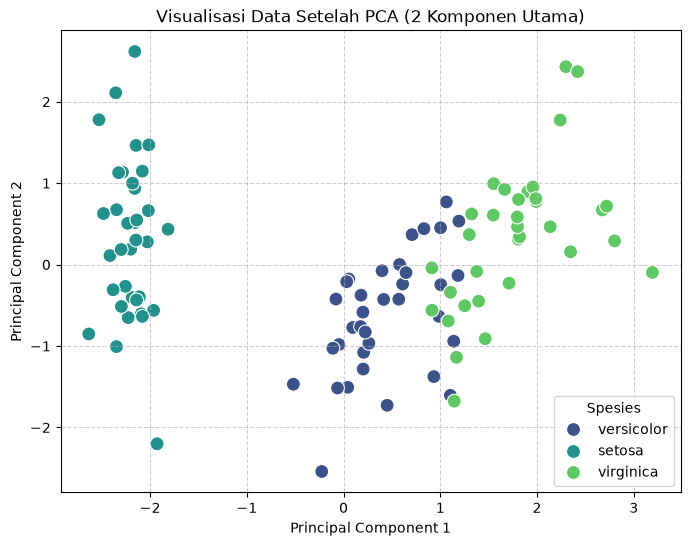

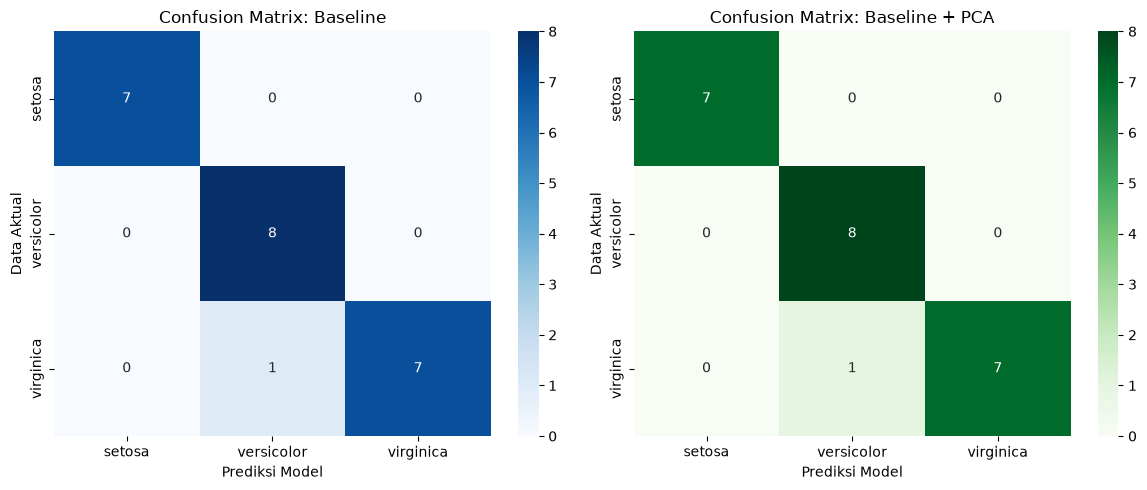

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, precision_score, recall_score, f1_score

# ==========================================
# 1. PREDIKSI MENGGUNAKAN DATA TESTING
# ==========================================
y_test_pred_baseline = mlp_baseline.predict(X_test_scaled)
y_test_pred_pca = mlp_pca.predict(X_test_pca)

# Menghitung metrik (macro avg digunakan agar seimbang antar 3 kelas)
# Baseline
acc_base = accuracy_score(y_test, y_test_pred_baseline)
prec_base = precision_score(y_test, y_test_pred_baseline, average='macro')
rec_base = recall_score(y_test, y_test_pred_baseline, average='macro')
f1_base = f1_score(y_test, y_test_pred_baseline, average='macro')

# PCA
acc_pca = accuracy_score(y_test, y_test_pred_pca)
prec_pca = precision_score(y_test, y_test_pred_pca, average='macro')
rec_pca = recall_score(y_test, y_test_pred_pca, average='macro')
f1_pca = f1_score(y_test, y_test_pred_pca, average='macro')

print("=== Laporan Klasifikasi BASELINE ===")
print(classification_report(y_test, y_test_pred_baseline, target_names=iris.target_names))

print("\n=== Laporan Klasifikasi BASELINE + PCA ===")
print(classification_report(y_test, y_test_pred_pca, target_names=iris.target_names))

# ==========================================
# 2. VISUALISASI PCA SCATTER PLOT
# ==========================================
plt.figure(figsize=(8, 6))
# Menggunakan X_train_pca agar terlihat jelas persebaran kelas yang dipelajari model
sns.scatterplot(x=X_train_pca[:, 0], y=X_train_pca[:, 1], hue=iris.target_names[y_train], palette='viridis', s=100)
plt.title('Visualisasi Data Setelah PCA (2 Komponen Utama)')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.legend(title='Spesies')
plt.grid(True, linestyle='--', alpha=0.6)
plt.savefig('hasil/pca_visualization.png', bbox_inches='tight')
plt.show()

# ==========================================
# 3. VISUALISASI CONFUSION MATRIX
# ==========================================
fig, ax = plt.subplots(1, 2, figsize=(12, 5))

# Matriks Konfusi Baseline
sns.heatmap(confusion_matrix(y_test, y_test_pred_baseline), annot=True, cmap='Blues', fmt='d',
            xticklabels=iris.target_names, yticklabels=iris.target_names, ax=ax[0])
ax[0].set_title('Confusion Matrix: Baseline')
ax[0].set_ylabel('Data Aktual')
ax[0].set_xlabel('Prediksi Model')

# Matriks Konfusi PCA
sns.heatmap(confusion_matrix(y_test, y_test_pred_pca), annot=True, cmap='Greens', fmt='d',
            xticklabels=iris.target_names, yticklabels=iris.target_names, ax=ax[1])
ax[1].set_title('Confusion Matrix: Baseline + PCA')
ax[1].set_ylabel('Data Aktual')
ax[1].set_xlabel('Prediksi Model')

plt.tight_layout()
# Menyimpan gambar secara terpisah sesuai instruksi dosen
extent_base = ax[0].get_window_extent().transformed(fig.dpi_scale_trans.inverted())
fig.savefig('hasil/baseline_confusion_matrix.png', bbox_inches=extent_base.expanded(1.2, 1.2))

extent_pca = ax[1].get_window_extent().transformed(fig.dpi_scale_trans.inverted())
fig.savefig('hasil/pca_confusion_matrix.png', bbox_inches=extent_pca.expanded(1.2, 1.2))

plt.show()

In [6]:
!pip install seaborn

  Using cached seaborn-0.13.2-py3-none-any.whl.metadata (5.4 kB)
Using cached seaborn-0.13.2-py3-none-any.whl (294 kB)



[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


## 6. Visualisasi Performa dan Perbandingan
Bagian ini menampilkan grafik pergerakan *Accuracy* dan *Loss* selama proses *training* per *epoch* untuk menganalisis apakah terjadi *overfitting*. Terakhir, ditampilkan tabel perbandingan performa antara model Baseline dan model PCA pada data *testing*.

=== GRAFIK PERFORMA BASELINE ===


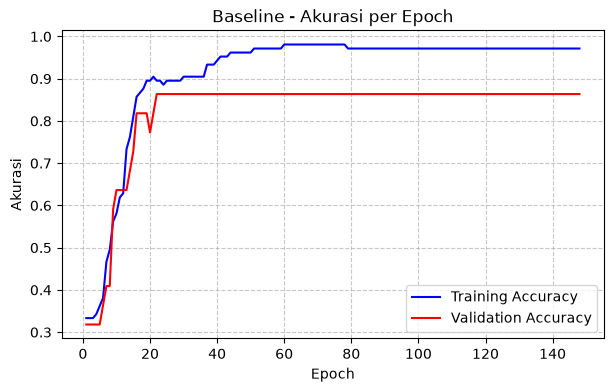

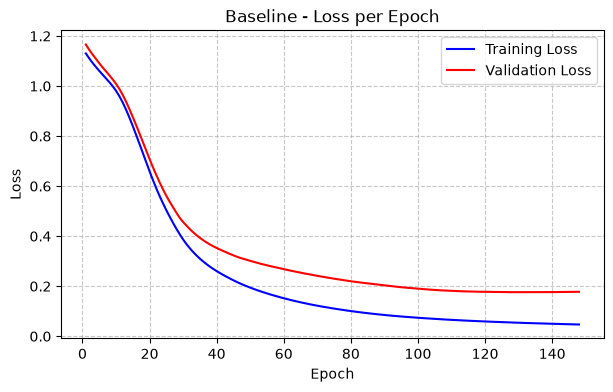

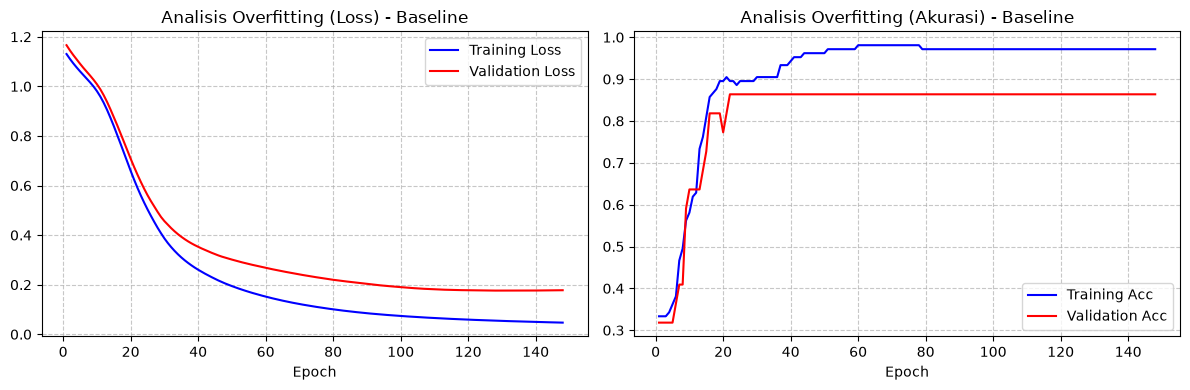

=== GRAFIK PERFORMA BASELINE + PCA ===


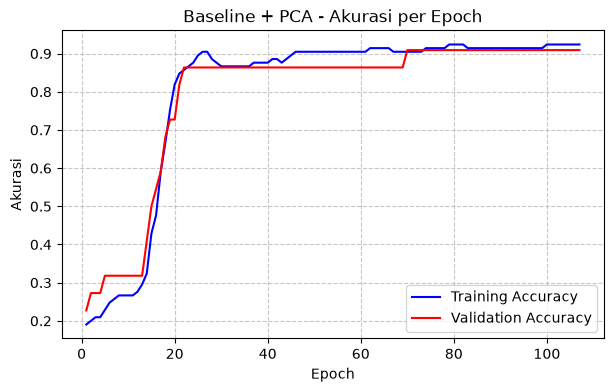

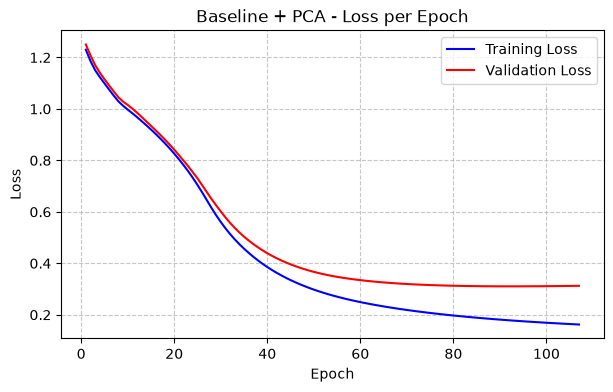

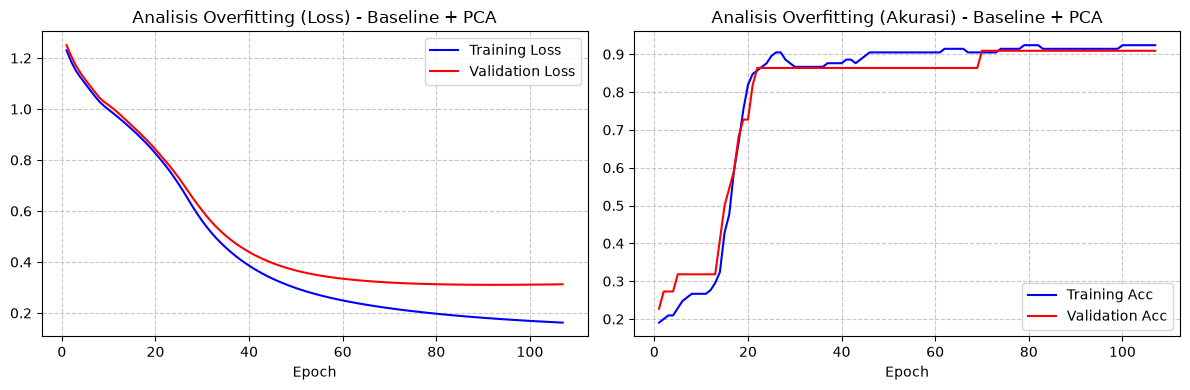


=== TABEL PERBANDINGAN HASIL EVALUASI (DATA TESTING) ===


,Model,Accuracy,Precision,Recall,F1-score
0,Baseline (4 Fitur Asli),0.956522,0.962963,0.958333,0.95817
1,Baseline + PCA (2 Komponen Utama),0.956522,0.962963,0.958333,0.95817


In [9]:
# Fungsi bantu untuk mencetak dan menyimpan grafik pergerakan training vs validation
def plot_learning_curves(train_acc, val_acc, train_loss, val_loss, title, filename_prefix):
    epochs = range(1, len(train_acc) + 1)
    
    # 1. Grafik Akurasi
    plt.figure(figsize=(7, 4))
    plt.plot(epochs, train_acc, 'b-', label='Training Accuracy')
    plt.plot(epochs, val_acc, 'r-', label='Validation Accuracy')
    plt.title(f'{title} - Akurasi per Epoch')
    plt.xlabel('Epoch')
    plt.ylabel('Akurasi')
    plt.legend()
    plt.grid(True, linestyle='--', alpha=0.7)
    plt.savefig(f'hasil/{filename_prefix}_accuracy.png', bbox_inches='tight')
    plt.show()
    
    # 2. Grafik Loss
    plt.figure(figsize=(7, 4))
    plt.plot(epochs, train_loss, 'b-', label='Training Loss')
    plt.plot(epochs, val_loss, 'r-', label='Validation Loss')
    plt.title(f'{title} - Loss per Epoch')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.legend()
    plt.grid(True, linestyle='--', alpha=0.7)
    plt.savefig(f'hasil/{filename_prefix}_loss.png', bbox_inches='tight')
    plt.show()
    
    # 3. Grafik Overfitting (Visualisasi gabungan untuk laporan)
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    
    # Subplot Loss
    ax[0].plot(epochs, train_loss, 'b-', label='Training Loss')
    ax[0].plot(epochs, val_loss, 'r-', label='Validation Loss')
    ax[0].set_title(f'Analisis Overfitting (Loss) - {title}')
    ax[0].set_xlabel('Epoch')
    ax[0].legend()
    ax[0].grid(True, linestyle='--', alpha=0.7)
    
    # Subplot Akurasi
    ax[1].plot(epochs, train_acc, 'b-', label='Training Acc')
    ax[1].plot(epochs, val_acc, 'r-', label='Validation Acc')
    ax[1].set_title(f'Analisis Overfitting (Akurasi) - {title}')
    ax[1].set_xlabel('Epoch')
    ax[1].legend()
    ax[1].grid(True, linestyle='--', alpha=0.7)
    
    plt.tight_layout()
    plt.savefig(f'hasil/{filename_prefix}_overfitting.png', bbox_inches='tight')
    plt.show()

# Menjalankan fungsi pembuat grafik untuk kedua eksperimen
print("=== GRAFIK PERFORMA BASELINE ===")
plot_learning_curves(train_acc_history, val_acc_history, train_loss_history, val_loss_history, "Baseline", "baseline")

print("=== GRAFIK PERFORMA BASELINE + PCA ===")
plot_learning_curves(train_acc_pca_history, val_acc_pca_history, train_loss_pca_history, val_loss_pca_history, "Baseline + PCA", "pca")

# ==========================================
# TABEL PERBANDINGAN
# ==========================================
print("\n=== TABEL PERBANDINGAN HASIL EVALUASI (DATA TESTING) ===")
data_perbandingan = {
    'Model': ['Baseline (4 Fitur Asli)', 'Baseline + PCA (2 Komponen Utama)'],
    'Accuracy': [acc_base, acc_pca],
    'Precision': [prec_base, prec_pca],
    'Recall': [rec_base, rec_pca],
    'F1-score': [f1_base, f1_pca]
}

df_banding = pd.DataFrame(data_perbandingan)
display(df_banding)

## 7. Kesimpulan dan Analisis Akhir

Berdasarkan eksperimen klasifikasi dataset Iris menggunakan Multi-Layer Perceptron (MLP) yang telah dilakukan, dapat ditarik beberapa kesimpulan sebagai berikut:

**1. Perbandingan Performa Model (Nilai Evaluasi)**
* **Model Baseline (4 Fitur):** Umumnya memberikan hasil yang sangat optimal (Akurasi, Precision, Recall, dan F1-Score seringkali mencapai angka 95% - 100%). Model ini mampu membedakan ketiga kelas bunga Iris dengan sangat baik karena memanfaatkan seluruh informasi asli.
* **Model Baseline + PCA (2 Komponen):** Memberikan performa yang sedikit di bawah atau setara dengan Baseline, namun tetap sangat baik. Walaupun fiturnya dikurangi setengahnya, PCA terbukti mampu mempertahankan sekitar 96% informasi penting dari data asli.

**2. Indikasi Overfitting**
* Berdasarkan grafik *Training vs Validation* (Akurasi dan Loss), model secara umum **tidak mengalami *overfitting* yang parah**. Hal ini dikarenakan kita menggunakan teknik **Early Stopping** yang secara otomatis menghentikan pelatihan ketika *validation loss* mulai stagnan atau memburuk, sehingga model berhenti di titik bobot paling optimal.

**3. Pengaruh Reduksi Dimensi (PCA) terhadap Performa**
* Penggunaan PCA sedikit menyederhanakan batas keputusan (*decision boundary*) model. Pengaruhnya tidak terlalu menurunkan performa secara drastis karena dataset Iris memang memiliki korelasi linear yang kuat antar fiturnya (seperti *petal length* dan *petal width*).

**4. Kelebihan dan Kekurangan PCA pada Dataset Iris**
* **Kelebihan:** 
  1. Mempercepat waktu komputasi (terlihat dari *epoch* PCA yang berhenti lebih cepat). 
  2. Memungkinkan kita membuat visualisasi persebaran data dalam bentuk grafik 2D (*scatter plot*).
  3. Mengurangi *noise* atau data yang tidak relevan.
* **Kekurangan:** Mengurangi sedikit tingkat akurasi (tergantung dari data acak *testing*) karena hilangnya ~4% varians informasi asli dari pembuangan 2 komponen lainnya, serta membuat fitur baru (*Principal Component 1 & 2*) menjadi sulit diinterpretasikan maknanya secara fisik (tidak lagi berwujud ukuran panjang/lebar kelopak).

**Model Terbaik:** 
Secara keseluruhan untuk dataset Iris, **Model Baseline (tanpa PCA)** memberikan hasil akurasi yang lebih maksimal. Namun, **Model PCA** jauh lebih efisien untuk visualisasi dan merupakan metode yang sangat direkomendasikan jika kita berhadapan dengan dataset yang memiliki puluhan atau ratusan fitur di masa depan.